# 05 — Risco econômico e melhor data de semeadura

Para cada município × data de semeadura, a margem do milho 2ª safra é simulada nos 26 anos com custo
disponível (colheitas 2000–2025), **pareando o clima, o preço do mês de colheita e o custo do mesmo
ano**, e sorteando a produtividade a partir dos quantis do modelo híbrido (notebook 03).

- **Margem** = preço × produtividade × (1 − Funrural) − (custo operacional por ha + custo por kg × produtividade) + indenização do seguro.
- **ZARC oficial**: tábua de risco da safra 2026/2027 (Portaria SPA/MAPA nº 329/2026; dados abertos do
  MAPA), milho 2ª safra, sequeiro, **Grupo I** (ciclo mais precoce; Grupo II como sensibilidade). A classe
  de água disponível do solo (AD1–AD6, IN SPA/MAPA nº 1/2022) de cada município vem da DTA municipal.
  Uma data é apta quando o decêndio correspondente tem risco indicado (20, 30 ou 40%).
- **Risco da lavoura**: o modelo prevê o rendimento médio do município; a lavoura individual varia mais.
  A variância idiossincrática (τ², em log) é calibrada para que a frequência de rendimento abaixo de 65%
  do esperado reproduza a fração de apólices indenizadas do PSR no Paraná (2016–2024).
- **Seguro**: só combinações aptas no ZARC têm acesso ao seguro rural subvencionado/PROAGRO. Seguro de
  produtividade com cobertura de 65% da produtividade esperada; nas inaptas não há indenização e o
  prêmio sai do custo.
- **Premissas e fontes**:
  - *Funrural* 1,5% da receita bruta = 1,2% (previdência) + 0,1% (RAT) + 0,2% (SENAR), pessoa física
    — Lei 8.212/1991, art. 25, com redação da Lei 13.606/2018.
  - *Cobertura do seguro* 65% da produtividade esperada: nível de 75% das 132.673 apólices de milho
    2ª safra no PR subvencionadas pelo PSR em 2016–2025 (19% em 70%; dados abertos do SISSER/MAPA,
    `dados/psr_milho2safra_pr_resumo_anual.csv`). Sensibilidade com 70%.
  - *Acesso ao seguro só dentro do ZARC*: a subvenção ao prêmio (PSR) e o PROAGRO exigem o plantio
    conforme o zoneamento (MCR, cap. 16; normas do PSR).
  - *Maturação fisiológica → venda* em 20 dias: na camada preta o grão tem ~30–35% de umidade e é
    colhido com 18–22% (Embrapa Milho e Sorgo); a secagem no campo é de 0,4–0,8 ponto percentual por
    dia (Iowa State University; Purdue), ou seja, 15–25 dias. Sensibilidade com 10 e 30 dias.
- **Decisão**: equivalente certo (CE) com utilidade exponencial (CARA) numa faixa de aversão a risco
  — *stochastic efficiency with respect to a function*, SERF (Hardaker et al., 2004) —, probabilidade
  de prejuízo e CVaR 10% (média dos 10% piores resultados).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.special import logsumexp
from scipy.stats import norm

import mapas
from sensibilidade import SAIDA, SENS, entrada

RAIZ = Path.cwd().parent
DADOS, RESULTADOS, FIGURAS = RAIZ / "dados", RAIZ / "resultados", RAIZ / "figuras"
if SENS:
    FIGURAS = SAIDA
rng = np.random.default_rng(42)

ORDEM_DATAS = [f"{d:02d}/{m:02d}" for m in (1, 2, 3) for d in (5, 15, 25)]
ANOS = range(2000, 2026)
N_SORTEIOS = 200
DIAS_ATE_VENDA = 20          # maturação fisiológica → colheita e venda
FUNRURAL = 0.015             # contribuição sobre a receita bruta (pessoa física, Lei 13.606/2018)
COBERTURA = 0.65             # nível de cobertura do seguro de produtividade
RISCO_RELATIVO = [0, 0.5, 1, 2, 3, 4]  # Anderson & Dillon (1992): 0,5 pouco ... 4 extremamente avesso
RR_REFERENCIA = 2
GRUPO_ZARC = 20              # Grupo I (tábua do ZARC: 20 = Grupo I, 21 = Grupo II)
JANELA = ["15/01", "25/01", "05/02", "15/02", "25/02", "05/03", "15/03"]
DECENDIO = {f"{d:02d}/{m:02d}": (m - 1) * 3 + {5: 1, 15: 2, 25: 3}[d] for m in (1, 2, 3) for d in (5, 15, 25)}

prod = pd.read_parquet(entrada("produtividade_prevista_pr.parquet"))
# Decisão só onde há histórico de 2ª safra no IBGE (fora disso o modelo extrapola: planalto frio, sem safrinha)
print("Municípios sem histórico de 2ª safra (fora da análise):", prod.loc[prod["sem_historico_ibge"], "cod_ibge"].nunique())
prod = prod[~prod["sem_historico_ibge"]]
sim = pd.read_parquet(entrada("simulacao_mza_pr.parquet"),
                      columns=["cod_ibge", "ano", "semeadura", "zarc_ISNA_I", "zarc_ISNA_III",
                               "zarc_tmed_floracao", "zarc_geada_I_III"])
custos = pd.read_csv(RESULTADOS / "custos_milho_safrinha_real.csv").set_index("ano")
precos = pd.read_csv(RESULTADOS / "precos_milho_pr_mensal_real.csv").set_index(["ano", "mes"])["preco_real_kg"]
mun = pd.read_csv(DADOS / "municipios_pr.csv").set_index("cod_ibge")

Municípios sem histórico de 2ª safra (fora da análise): 26


## 1. ZARC oficial (tábua de risco 2026/2027)

In [2]:
# Classe de água disponível (mm/cm) pela DTA municipal — limites da IN SPA/MAPA nº 1/2022
LIMITES_AD = [0, 0.465, 0.615, 0.805, 1.065, 1.405, 99]
mun["cod_solo_ad"] = pd.cut(mun["dta_mm_m"] / 100, LIMITES_AD, labels=[11, 12, 13, 14, 15, 16]).astype(int)
print(mun["cod_solo_ad"].map({11: "AD1", 12: "AD2", 13: "AD3", 14: "AD4", 15: "AD5", 16: "AD6"}).value_counts().sort_index().to_dict())

tabua = pd.read_csv(DADOS / "zarc_milho2safra_pr_2026_2027.csv")
tabua = tabua.drop_duplicates(["geocodigo", "Cod_Ciclo", "Cod_Solo"])


def zarc_oficial(grupo):
    t = tabua[tabua["Cod_Ciclo"] == grupo].set_index(["geocodigo", "Cod_Solo"])
    linhas = []
    for cod, ad in mun["cod_solo_ad"].items():
        for data, dec in DECENDIO.items():
            risco = t.at[(cod, ad), f"dec{dec}"] if (cod, ad) in t.index else 0
            linhas.append({"cod_ibge": cod, "semeadura": data, "risco_zarc": int(risco)})
    z = pd.DataFrame(linhas)
    z["classe_zarc"] = z["risco_zarc"].map({20: "20%", 30: "30%", 40: "40%"}).fillna("Inapto")
    z["apto"] = z["risco_zarc"] > 0
    return z


zarc = zarc_oficial(GRUPO_ZARC)
pd.crosstab(zarc["semeadura"], zarc["classe_zarc"]).loc[ORDEM_DATAS, ["20%", "30%", "40%", "Inapto"]]

{'AD2': 17, 'AD3': 44, 'AD4': 54, 'AD5': 263, 'AD6': 21}


classe_zarc,20%,30%,40%,Inapto
semeadura,,,,
05/01,333,41,21,4
15/01,280,57,34,28
25/01,219,79,56,45
05/02,128,97,87,87
15/02,120,85,69,125
25/02,82,95,75,147
05/03,155,48,37,159
15/03,120,88,18,173
25/03,0,0,0,399


### 1.1 A réplica do balanço hídrico do ZARC concorda com o ZARC oficial?

Teste do próprio MZA: a réplica do critério hídrico da portaria (ciclo de 100 dias; adverso se ISNA da
fase I ≤ 0,70 ou da fase III ≤ 0,55; apta se ≤ 40% dos anos adversos) comparada com a tábua oficial.

In [3]:
sim["adverso"] = (sim["zarc_ISNA_I"] <= 0.70) | (sim["zarc_ISNA_III"] <= 0.55)
replica = sim.groupby(["cod_ibge", "semeadura"])["adverso"].mean().rename("freq_adverso_replica").reset_index()
cmp_z = zarc.merge(replica, on=["cod_ibge", "semeadura"])
cmp_z["apto_replica"] = cmp_z["freq_adverso_replica"] <= 0.40
concord = (cmp_z["apto"] == cmp_z["apto_replica"]).mean()
print(f"Concordância apto/inapto réplica × oficial: {concord:.1%}")
pd.crosstab(cmp_z["apto"], cmp_z["apto_replica"], rownames=["oficial"], colnames=["réplica"])

Concordância apto/inapto réplica × oficial: 39.1%


réplica,False,True
oficial,,
False,568,599
True,1587,837


## 2. Preço do mês de colheita e estrutura de custo

In [4]:
det = pd.read_excel(DADOS / "custos.xlsx", sheet_name="so_a_base", header=None)
itens = det.iloc[5:, [1, 5, 11]]
itens.columns = ["cultura", "item", "valor"]
milho2 = itens[itens["cultura"] == 7].set_index("item")["valor"].apply(pd.to_numeric, errors="coerce").fillna(0)
VARIAVEIS = ["Operação de máquinas e implementos", "Despesas de manutenção de benfeitorias", "Mão-de-obra temporária",
             "Sementes/Manivas", "Fertilizantes", "Agrotóxicos", "Despesas gerais", "Transporte externo",
             "Assistência técnica", "PROAGRO/SEGURO", "Juros"]
FRAC_PREMIO = milho2["PROAGRO/SEGURO"] / milho2[VARIAVEIS].sum()
print(f"Prêmio PROAGRO/seguro = {FRAC_PREMIO:.1%} do custo variável (DERAL, mai/2026)")

df = prod[prod["ano"].isin(ANOS)].merge(zarc[["cod_ibge", "semeadura", "classe_zarc", "apto"]],
                                         on=["cod_ibge", "semeadura"])


def preco_de_venda(dias):
    venda = pd.to_datetime(df["data_maturacao"]) + pd.Timedelta(days=dias)
    return precos.reindex(pd.MultiIndex.from_arrays([venda.dt.year, venda.dt.month])).to_numpy(), venda.dt.month


df["preco_kg"], df["mes_venda"] = preco_de_venda(DIAS_ATE_VENDA)
c = custos.reindex(df["ano"])
df["custo_ha"] = c["custo_operacional_ha_fixo"].to_numpy()
df["custo_ha_total"] = c["custo_total_ha_fixo"].to_numpy()
df["custo_kg"] = c["custo_var_real_kg"].to_numpy()
df["premio_ha"] = FRAC_PREMIO * c["custo_var_real_ha"].to_numpy()
print(df["preco_kg"].isna().sum(), "combinações sem preço")
df.groupby("semeadura")[["mes_venda", "preco_kg"]].mean().loc[ORDEM_DATAS].round(2).T

Prêmio PROAGRO/seguro = 7.0% do custo variável (DERAL, mai/2026)
0 combinações sem preço


semeadura,05/01,15/01,25/01,05/02,15/02,25/02,05/03,15/03,25/03
mes_venda,5.04,5.55,6.01,6.73,7.29,7.87,8.31,8.84,9.28
preco_kg,0.84,0.83,0.82,0.81,0.81,0.81,0.81,0.82,0.83


## 3. Risco da lavoura (calibração com o PSR) e Monte Carlo da margem

log Y_lavoura = log Y_município + ε, ε ~ N(0, τ²). O desvio σ do município vem dos quantis do modelo
híbrido; τ é o único parâmetro calibrado: minimiza o erro entre a frequência anual de rendimento
< 65% do esperado (datas aptas da janela) e a fração de apólices indenizadas no PSR, 2016–2024.

In [5]:
mu = np.log(df["rend_P50_kg_ha"].to_numpy())
sigma = (np.log(df["rend_P90_kg_ha"]) - np.log(df["rend_P10_kg_ha"])).to_numpy() / (2 * norm.ppf(0.9))
y_esperado = df.groupby(["cod_ibge", "semeadura"])["rend_P50_kg_ha"].transform("mean").to_numpy()

psr = pd.read_csv(DADOS / "psr_milho2safra_pr_resumo_anual.csv").set_index("ano")
alvo = psr.loc[2016:2024, "frac_indenizadas"]
sel = (df["semeadura"].isin(JANELA) & df["apto"] & df["ano"].between(2016, 2024)).to_numpy()
z_lim = np.log(COBERTURA * y_esperado[sel]) - mu[sel]


def freq_quebra(tau):
    p = norm.cdf(z_lim / np.sqrt(sigma[sel] ** 2 + tau ** 2))
    return pd.Series(p).groupby(df["ano"].to_numpy()[sel]).mean()


grade = np.arange(0, 0.80, 0.01)
erro = [((freq_quebra(t) - alvo) ** 2).sum() for t in grade]
TAU = float(grade[int(np.argmin(erro))])
comp_psr = pd.DataFrame({"modelo_municipio": freq_quebra(0.0), "modelo_lavoura": freq_quebra(TAU), "psr": alvo})
print(f"τ calibrado = {TAU:.2f} (σ médio do município = {sigma.mean():.2f}); "
      f"r anual lavoura × PSR = {comp_psr['modelo_lavoura'].corr(comp_psr['psr']):.2f}")
sigma_lav = np.sqrt(sigma ** 2 + TAU ** 2)
Y = np.exp(mu[:, None] + sigma_lav[:, None] * rng.standard_normal((len(df), N_SORTEIOS)))  # kg/ha, lavoura
comp_psr.round(3).T

τ calibrado = 0.36 (σ médio do município = 0.26); r anual lavoura × PSR = 0.89


,2016,2017,2018,2019,2020,2021,2022,2023,2024
modelo_municipio,0.119,0.022,0.234,0.070,0.222,0.467,0.068,0.055,0.197
modelo_lavoura,0.218,0.109,0.298,0.165,0.302,0.471,0.155,0.151,0.277
psr,0.378,0.055,0.441,0.156,0.270,0.675,0.184,0.019,0.183


In [6]:
apto = df["apto"].to_numpy()[:, None]


def margem(custo_ha, com_seguro=True, cobertura=COBERTURA, preco=None):
    preco = df["preco_kg"].to_numpy() if preco is None else preco
    preco_seguro = pd.Series(preco).groupby([df["cod_ibge"].to_numpy(), df["semeadura"].to_numpy()]).transform("mean")
    receita = preco[:, None] * Y * (1 - FUNRURAL)
    custo = custo_ha.to_numpy()[:, None] + df["custo_kg"].to_numpy()[:, None] * Y
    if com_seguro:
        indenizacao = np.maximum(cobertura * y_esperado[:, None] - Y, 0) * preco_seguro.to_numpy()[:, None]
        return receita - custo + np.where(apto, indenizacao, 0)
    return receita - custo + df["premio_ha"].to_numpy()[:, None]  # sem seguro: não paga prêmio


M = {"operacional": margem(df["custo_ha"]),
     "operacional_sem_seguro": margem(df["custo_ha"], com_seguro=False),
     "total": margem(df["custo_ha_total"])}
ESCALA_W = float(custos.loc[list(ANOS), "custo_total_real_ha"].mean())  # R$/ha: capital em risco
print(f"Escala de riqueza para a aversão absoluta: R$ {ESCALA_W:,.0f}/ha")

Escala de riqueza para a aversão absoluta: R$ 4,239/ha


In [7]:
grupos = df.groupby(["cod_ibge", "semeadura"]).indices


def resumo(m):
    linhas = []
    for (cod, data), idx in grupos.items():
        v = m[idx].ravel()
        pior = np.sort(v)[: max(1, int(0.10 * v.size))]
        lin = {"cod_ibge": cod, "semeadura": data, "margem_media": v.mean(), "p_prejuizo": (v < 0).mean(),
               "cvar10": pior.mean()}
        for rr in RISCO_RELATIVO:
            ra = rr / ESCALA_W
            lin[f"CE_rr{rr}"] = v.mean() if ra == 0 else -(logsumexp(-ra * v) - np.log(v.size)) / ra
        linhas.append(lin)
    return pd.DataFrame(linhas)


res = {k: resumo(m) for k, m in M.items()}
risco = (res["operacional"].merge(zarc, on=["cod_ibge", "semeadura"])
         .merge(res["operacional_sem_seguro"][["cod_ibge", "semeadura", f"CE_rr{RR_REFERENCIA}", "p_prejuizo"]]
                .rename(columns={f"CE_rr{RR_REFERENCIA}": "CE_sem_seguro", "p_prejuizo": "p_prejuizo_sem_seguro"}),
                on=["cod_ibge", "semeadura"])
         .merge(res["total"][["cod_ibge", "semeadura", "margem_media", "p_prejuizo"]]
                .rename(columns={"margem_media": "margem_media_custo_total", "p_prejuizo": "p_prejuizo_custo_total"}),
                on=["cod_ibge", "semeadura"]))
risco["valor_seguro"] = np.where(risco["apto"], risco[f"CE_rr{RR_REFERENCIA}"] - risco["CE_sem_seguro"], np.nan)
risco.to_csv(SAIDA / "risco_economico_municipio_data.csv", index=False)
risco.groupby("semeadura")[["margem_media", "p_prejuizo", "cvar10", f"CE_rr{RR_REFERENCIA}", "valor_seguro",
                            "margem_media_custo_total"]].mean().loc[ORDEM_DATAS].round(2)

,margem_media,p_prejuizo,cvar10,CE_rr2,valor_seguro,margem_media_custo_total
semeadura,,,,,,
05/01,1846.11,0.26,-1017.53,855.23,91.11,885.45
15/01,1616.48,0.28,-1163.45,712.79,78.40,655.82
25/01,1407.03,0.31,-1273.69,579.52,76.33,446.37
05/02,1281.64,0.34,-1385.83,448.06,87.27,320.99
15/02,1169.67,0.37,-1467.53,354.11,74.71,209.01
25/02,1180.41,0.36,-1532.59,356.06,68.94,219.75
05/03,1301.01,0.34,-1548.87,416.93,66.22,340.35
15/03,1422.06,0.33,-1533.98,475.80,58.78,461.40
25/03,1350.01,0.35,-1781.30,334.02,NaN,389.35


## 4. Melhor data por município

In [8]:
CE = f"CE_rr{RR_REFERENCIA}"


def melhor(df_r, so_apto):
    d = df_r[df_r["apto"]] if so_apto else df_r
    return d.loc[d.groupby("cod_ibge")[CE].idxmax()].set_index("cod_ibge")


melhor_apto = melhor(risco, True)
melhor_livre = melhor(risco, False)
neutro = risco.loc[risco.groupby("cod_ibge")["CE_rr0"].idxmax()].set_index("cod_ibge")["semeadura"]
decisao = pd.DataFrame({
    "municipio": mun["municipio"],
    "melhor_data_zarc": melhor_apto["semeadura"],
    "CE_melhor_data_zarc": melhor_apto[CE],
    "p_prejuizo_melhor_data_zarc": melhor_apto["p_prejuizo"],
    "melhor_data_sem_restricao": melhor_livre["semeadura"],
    "melhor_data_risco_neutro": neutro,
})
decisao["sem_data_apta"] = decisao["melhor_data_zarc"].isna()
decisao["muda_com_aversao"] = decisao["melhor_data_sem_restricao"] != decisao["melhor_data_risco_neutro"]
decisao.to_csv(SAIDA / "melhor_data_semeadura_pr.csv")
print("Municípios sem nenhuma data apta no ZARC:", int(decisao["sem_data_apta"].sum()))
print("Melhor data muda entre risco neutro e rr=2:", int(decisao["muda_com_aversao"].sum()))
decisao["melhor_data_zarc"].value_counts().reindex(ORDEM_DATAS).fillna(0).astype(int).to_frame().T

Municípios sem nenhuma data apta no ZARC: 27
Melhor data muda entre risco neutro e rr=2: 72


melhor_data_zarc,05/01,15/01,25/01,05/02,15/02,25/02,05/03,15/03,25/03
count,310,21,4,2,0,2,10,23,0


## 5. Mapas

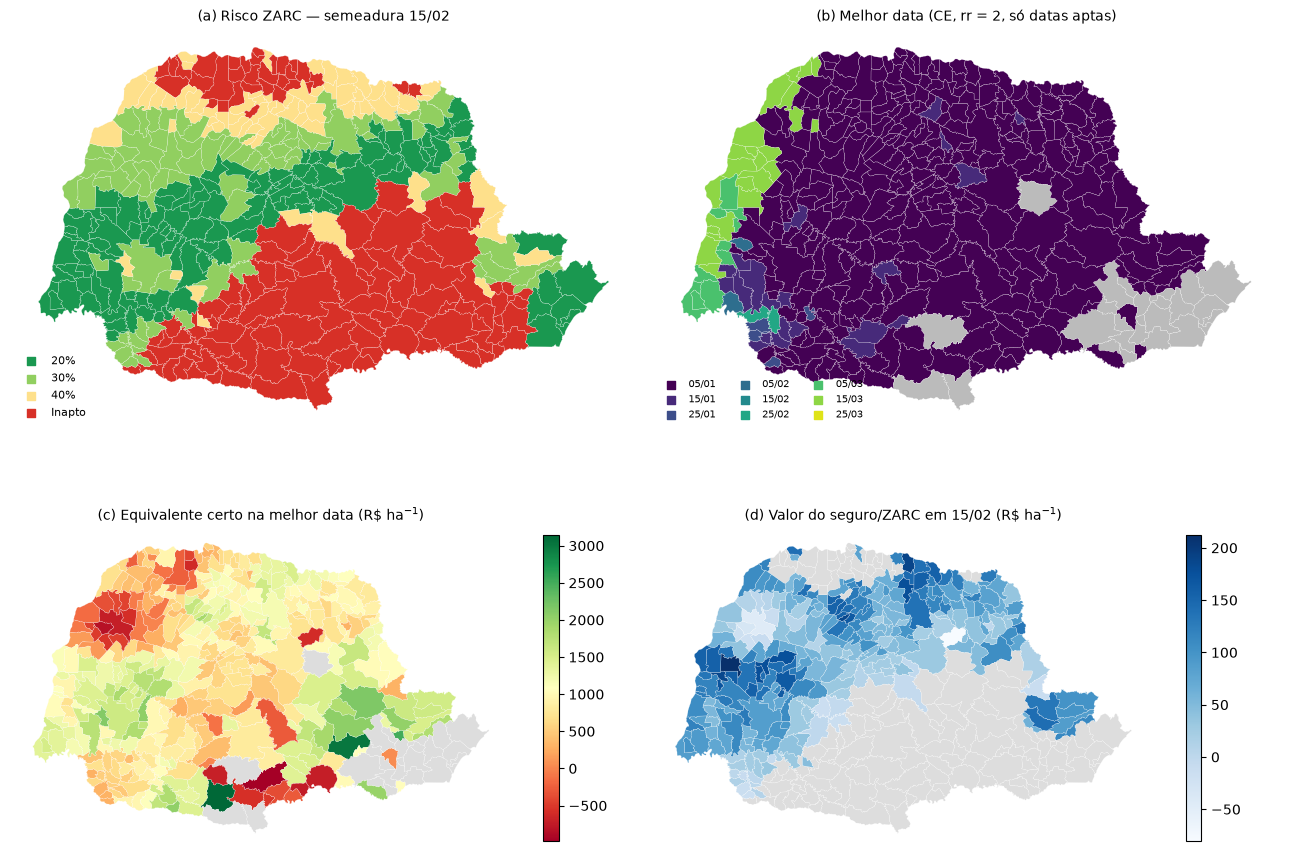

In [9]:
fig, axs = plt.subplots(2, 2, figsize=(13, 10))
cores_zarc = ["#1a9850", "#91cf60", "#fee08b", "#d73027"]
z15 = zarc[zarc["semeadura"] == "15/02"].set_index("cod_ibge")["classe_zarc"].astype(str)
mapas.mapa(axs[0, 0], z15, categorias=["20%", "30%", "40%", "Inapto"], cores=cores_zarc,
           titulo="(a) Risco ZARC — semeadura 15/02")
cores_datas = plt.cm.viridis(np.linspace(0, 0.95, len(ORDEM_DATAS)))
mapas.mapa(axs[0, 1], decisao["melhor_data_zarc"].fillna("sem data apta"),
           categorias=ORDEM_DATAS + ["sem data apta"], cores=list(cores_datas) + ["#bbbbbb"],
           titulo=f"(b) Melhor data (CE, rr = {RR_REFERENCIA}, só datas aptas)")
sm = mapas.mapa(axs[1, 0], decisao["CE_melhor_data_zarc"], cmap="RdYlGn",
                titulo=r"(c) Equivalente certo na melhor data (R\$ ha$^{-1}$)")
fig.colorbar(sm, ax=axs[1, 0], shrink=0.6)
vs = risco[risco["semeadura"] == "15/02"].set_index("cod_ibge")["valor_seguro"]
sm = mapas.mapa(axs[1, 1], vs, cmap="Blues", titulo=r"(d) Valor do seguro/ZARC em 15/02 (R\$ ha$^{-1}$)")
fig.colorbar(sm, ax=axs[1, 1], shrink=0.6)
for i, (cat, cor) in enumerate(zip(["20%", "30%", "40%", "Inapto"], cores_zarc)):
    axs[0, 0].scatter([], [], color=cor, label=cat, marker="s")
axs[0, 0].legend(frameon=False, loc="lower left", fontsize=8)
for d, cor in zip(ORDEM_DATAS, cores_datas):
    axs[0, 1].scatter([], [], color=cor, label=d, marker="s")
axs[0, 1].legend(frameon=False, loc="lower left", fontsize=7, ncol=3)
plt.tight_layout()
fig.savefig(FIGURAS / "fig_mapas_risco_decisao.png", dpi=300)

## 6. Curvas SERF (exemplos)

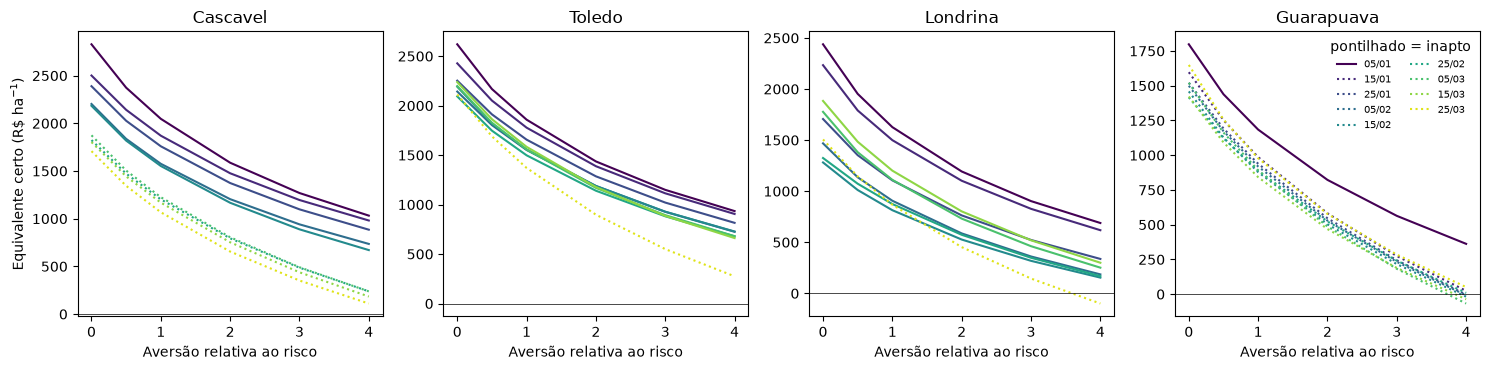

In [10]:
exemplos = ["Cascavel", "Toledo", "Londrina", "Guarapuava"]
fig, axs = plt.subplots(1, len(exemplos), figsize=(15, 3.8), sharey=False)
for ax, nome in zip(axs, exemplos):
    cod = mun.index[mun["municipio"] == nome][0]
    r = risco[risco["cod_ibge"] == cod].set_index("semeadura").loc[ORDEM_DATAS]
    for (data, linha), cor in zip(r.iterrows(), cores_datas):
        ax.plot(RISCO_RELATIVO, [linha[f"CE_rr{x}"] for x in RISCO_RELATIVO], color=cor,
                ls="-" if linha["apto"] else ":", label=data)
    ax.axhline(0, color="k", lw=0.5)
    ax.set(title=nome, xlabel="Aversão relativa ao risco")
axs[0].set_ylabel(r"Equivalente certo (R\$ ha$^{-1}$)")
axs[-1].legend(fontsize=7, frameon=False, ncol=2, title="pontilhado = inapto")
plt.tight_layout()
fig.savefig(FIGURAS / "fig_serf_exemplos.png", dpi=300)

## 7. Validação independente com o seguro rural (PSR)

Fração de apólices de milho 2ª safra indenizadas no Paraná (SISSER/MAPA) × probabilidade média de
rendimento abaixo de 65% do esperado (datas aptas da janela 15/01–15/03), no nível do município e da
lavoura. τ ajusta só o nível médio; a correlação entre anos é informação independente. 2025 fica fora:
as indenizações ainda não estão processadas nos dados abertos.

r de Pearson (2016–2024), município: 0.89; lavoura: 0.89


,2016,2017,2018,2019,2020,2021,2022,2023,2024
modelo_municipio,0.119,0.022,0.234,0.070,0.222,0.467,0.068,0.055,0.197
modelo_lavoura,0.218,0.109,0.298,0.165,0.302,0.471,0.155,0.151,0.277
psr,0.378,0.055,0.441,0.156,0.270,0.675,0.184,0.019,0.183


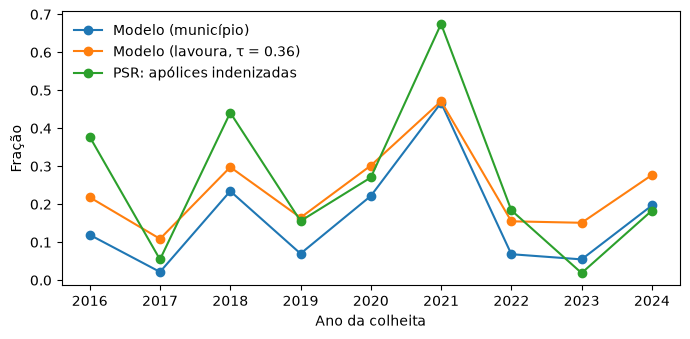

In [11]:
psr = pd.read_csv(DADOS / "psr_milho2safra_pr_resumo_anual.csv").set_index("ano")
comp = comp_psr
print(f"r de Pearson (2016–2024), município: {comp['modelo_municipio'].corr(comp['psr']):.2f}; "
      f"lavoura: {comp['modelo_lavoura'].corr(comp['psr']):.2f}")
fig, ax = plt.subplots(figsize=(7, 3.5))
comp.plot(ax=ax, marker="o")
ax.set(xlabel="Ano da colheita", ylabel="Fração")
ax.legend(["Modelo (município)", f"Modelo (lavoura, τ = {TAU:.2f})", "PSR: apólices indenizadas"], frameon=False)
plt.tight_layout()
fig.savefig(FIGURAS / "fig_validacao_psr.png", dpi=300)
comp.round(3).T

## 8. Sensibilidade: cobertura de 70% e 10/30 dias até a venda

In [12]:
def melhor_data(m, z):
    r = resumo(m).merge(z[["cod_ibge", "semeadura", "apto"]], on=["cod_ibge", "semeadura"])
    return r, melhor(r, True)["semeadura"]


zarc_g2 = zarc_oficial(21)
cenarios = {"custo total": (M["total"], zarc), "cobertura 70%": (margem(df["custo_ha"], cobertura=0.70), zarc)}
apto_base = apto.copy()
apto = df[["cod_ibge", "semeadura"]].merge(zarc_g2, on=["cod_ibge", "semeadura"], how="left")["apto"].fillna(False).to_numpy()[:, None]
cenarios["ZARC Grupo II"] = (margem(df["custo_ha"]), zarc_g2)
apto = apto_base
for dias in (10, 30):
    cenarios[f"{dias} dias até a venda"] = (margem(df["custo_ha"], preco=preco_de_venda(dias)[0]), zarc)
sens = []
for nome, (m, z) in cenarios.items():
    r, b = melhor_data(m, z)
    sens.append({"cenario": nome, "margem_media": r["margem_media"].mean(), "p_prejuizo": r["p_prejuizo"].mean(),
                 "mesma_melhor_data_%": 100 * b.eq(melhor_apto["semeadura"].reindex(b.index)).mean(),
                 "municipios_com_data_apta": b.size})
sens = pd.DataFrame(sens)
sens.to_csv(SAIDA / "sensibilidade_decisao.csv", index=False)
sens.round(2)

,cenario,margem_media,p_prejuizo,mesma_melhor_data_%,municipios_com_data_apta
0,custo total,436.50,0.52,94.09,372
1,cobertura 70%,1430.73,0.31,99.73,372
2,ZARC Grupo II,1391.85,0.33,96.34,355
3,10 dias até a venda,1404.54,0.33,91.13,372
4,30 dias até a venda,1395.17,0.33,90.86,372


## 9. Os modelos acertam o risco? Probabilidade de prejuízo fora da amostra

Com as previsões deixando um ano de fora (notebook 03), compara-se a probabilidade de prejuízo
prevista por município-ano com o prejuízo **observado** (rendimento IBGE, preço do mês de colheita
típico da janela, custo operacional do ano). Escore de Brier (menor = melhor) e curva de confiabilidade.

In [13]:
oof = pd.read_parquet(entrada("previsoes_fora_amostra.parquet"))
oof = oof[oof["ano"].isin(ANOS)].copy()
janela = sim.merge(prod[["cod_ibge", "ano", "semeadura", "data_maturacao"]], on=["cod_ibge", "ano", "semeadura"])
janela = janela[janela["semeadura"].isin(["15/01", "25/01", "05/02", "15/02", "25/02", "05/03", "15/03"])]
mat = janela.groupby(["cod_ibge", "ano"])["data_maturacao"].apply(lambda s: pd.to_datetime(s).mean())
oof = oof.merge(mat.rename("mat").reset_index(), on=["cod_ibge", "ano"])
v = oof["mat"] + pd.Timedelta(days=DIAS_ATE_VENDA)
oof["preco_kg"] = precos.reindex(pd.MultiIndex.from_arrays([v.dt.year, v.dt.month])).to_numpy()
co = custos.reindex(oof["ano"])
cf, ck = co["custo_operacional_ha_fixo"].to_numpy(), co["custo_var_real_kg"].to_numpy()
p_eq = oof["preco_kg"] * (1 - FUNRURAL) - ck                    # margem = p_eq·Y − cf
y_equilibrio = cf / p_eq                                          # rendimento de equilíbrio
oof["prejuizo_obs"] = oof["rendimento_kg_ha"] < y_equilibrio

MODELOS = ["A_media_historica", "B_MZA_calibrado", "C_ML_puro", "D_hibrido", "E_hibrido_monotonico",
           "F_hibrido_apsim", "H_hibrido_aquacrop", "I_hibrido_dssat", "J_hibrido_todos",
           "K_hibrido_svr", "L_ensemble_E_SVR"]
brier, conf = {}, {}
for m in MODELOS:
    res_m = oof["log_y"] - oof[m]
    p = np.empty(len(oof))
    for ano in oof["ano"].unique():
        r = res_m[oof["ano"] != ano].to_numpy()
        sel = (oof["ano"] == ano).to_numpy()
        # P(Y < y_eq) = fração dos resíduos dos outros anos abaixo de log(y_eq) − previsão
        lim = np.log(y_equilibrio[sel].to_numpy()) - oof.loc[sel, m].to_numpy()
        p[sel] = (r[None, :] < lim[:, None]).mean(axis=1)
    oof[f"p_{m}"] = p
    brier[m] = np.mean((p - oof["prejuizo_obs"]) ** 2)
    conf[m] = oof.groupby(pd.cut(p, np.linspace(0, 1, 11)), observed=True)["prejuizo_obs"].agg(["mean", "size"])
brier = pd.Series(brier, name="Brier")
clim = oof["prejuizo_obs"].mean()
print(f"Frequência observada de prejuízo: {clim:.1%}; Brier de referência (frequência constante): {clim * (1 - clim):.4f}")
brier.round(4).to_frame().T

Frequência observada de prejuízo: 56.0%; Brier de referência (frequência constante): 0.2464


,A_media_historica,B_MZA_calibrado,C_ML_puro,D_hibrido,E_hibrido_monotonico,F_hibrido_apsim,H_hibrido_aquacrop,I_hibrido_dssat,J_hibrido_todos,K_hibrido_svr,L_ensemble_E_SVR
Brier,0.1659,0.1634,0.1641,0.154,0.1609,0.1677,0.1735,0.1676,0.1653,0.1545,0.1558


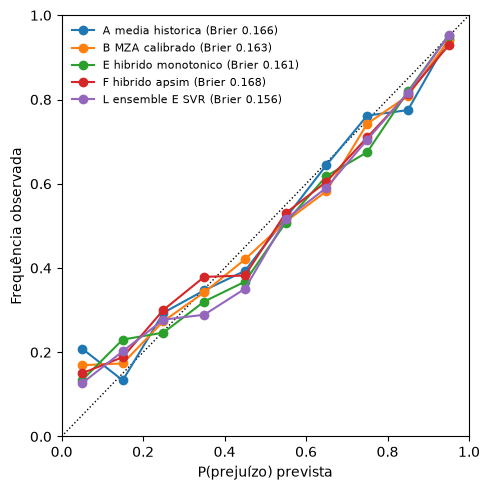

In [14]:
fig, ax = plt.subplots(figsize=(5, 5))
ax.plot([0, 1], [0, 1], "k:", lw=1)
for m in ["A_media_historica", "B_MZA_calibrado", "E_hibrido_monotonico", "F_hibrido_apsim", "L_ensemble_E_SVR"]:
    c = conf[m]
    centros = [iv.mid for iv in c.index]
    ax.plot(centros, c["mean"], "o-", label=f"{m.replace('_', ' ')} (Brier {brier[m]:.3f})")
ax.set(xlabel="P(prejuízo) prevista", ylabel="Frequência observada", xlim=(0, 1), ylim=(0, 1))
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()
fig.savefig(FIGURAS / "fig_confiabilidade_prejuizo.png", dpi=300)